In [36]:
%load_ext autoreload
%autoreload 2
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from collections import deque


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Check if it manages to load video

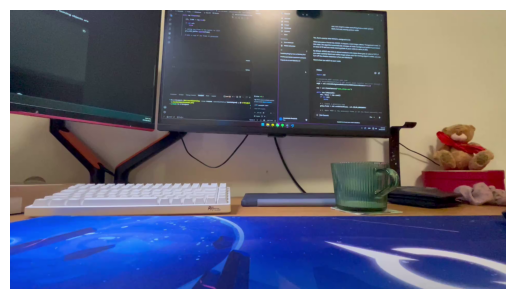

In [37]:
cap = cv.VideoCapture("test.mov")

if not cap.isOpened():
    print("Error opening video")

# read the first frame if there is a frame ret = true
ret, frame = cap.read()

if ret:
    frame_rgb = cv.cvtColor(frame, cv.COLOR_BGR2RGB)

    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()



    

### ROI definition

In [38]:
def roi(frame):
    pts = np.array([
        [355, 153],   # Top left
        [1578, 113],  # Top right
        [1621, 1020], # Bottom right
        [322, 1013]   # Bottom left
    ])

    # Needed for OpenCV to understand coordinates as a list
    pts = pts.reshape((-1, 1, 2))

    # Makes black and white mask:
    mask = np.zeros(frame.shape, dtype = np.uint8)
    cv.fillPoly(mask, [pts], (255,255,255))

    # Black = delete video pixels of original frame; White = let pixels through
    rect_img = cv.bitwise_and(frame, mask)

    return rect_img



In [39]:
def mog2(frame, fgbg_mog2):
    fgmask = fgbg_mog2.apply(frame)

    # Size of the filter
    # TODO: adjust kernel in real world situation
    kernel = np.ones((5,5), np.uint8)

    fgmask_erode = cv.erode(fgmask, kernel, iterations = 1)
    fgmask_final = cv.dilate(fgmask_erode, kernel, iterations = 1)

    return fgmask_final

### Make a circular ring buffer to store frames 

Starting video feed...


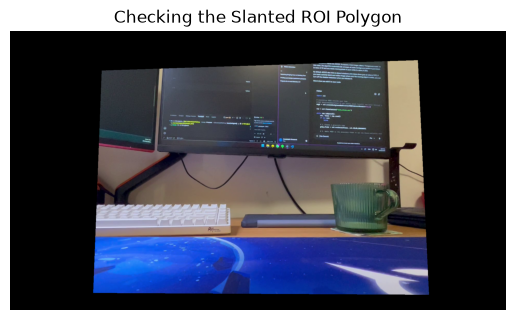

Object detected
Video saves as 'out.mp4'. Exiting...


In [40]:
pre_roll_buffer = deque(maxlen=200)
filter_buffer = deque()

# for MOG2 background subtraction
fgbg_mog2 = cv.createBackgroundSubtractorMOG2(history=500, varThreshold=100, detectShadows=False)
# VideoWriter needs exact width, height and FPS to create a valid video
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv.CAP_PROP_FPS)

#fourcc - four character code: used to identify which codec program should use to shirnk the file
fourcc = cv.VideoWriter_fourcc(*'mp4v')

# Filtered video to check if it's working correctly
out_filter = cv.VideoWriter("out_filter.mp4", fourcc, fps, (width, height), isColor=False)

print("Starting video feed...")

object_detected = False
frame_count = 0

while cap.isOpened():
    
    ret, frame = cap.read()

    if not ret:
        break

    # Adding new frame in color to the buffer
    pre_roll_buffer.append(frame)

    rect_image = roi(frame)

    # Checking if roi is working properly
    if frame_count == 1:
        # Convert BGR to RGB so the colors look normal
        plt.imshow(cv.cvtColor(rect_image, cv.COLOR_BGR2RGB))
        plt.title("Checking the Slanted ROI Polygon")
        plt.axis('off')
        plt.show()


    # MOG2 logic
    final_mask = mog2(rect_image, fgbg_mog2)
    frame_count += 1
      
    out_filter.write(final_mask)
    filter_buffer.clear()
    
    # TODO : add object detection logic

    # Simulate object detection for testing
    if frame_count > 300:
        object_detected = True

    if object_detected:
        print("Object detected")

        
        out = cv.VideoWriter("out.mp4", fourcc, fps, (width, height))
       
        # Write every frame that's currently in the buffer
        for buffered_frame in pre_roll_buffer:
            out.write(buffered_frame)
        out.release()
        pre_roll_buffer.clear()
        out_filter.release()

        print("Video saves as 'out.mp4'. Exiting...")

        break

    

cap.release() 